In [2]:
import scimap as sm

Running SCIMAP  2.3.4


In [1]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import anndata as ad
import scanpy as sc

In [2]:
import os
os.getcwd()

'C:\\Users\\tpeng\\Notebook_home_250910'

## download the adata object "Xenium_Proseq_pt4_control_neighborhood_261009.h5ad" from the GitHub page"

In [3]:
adata = sc.read ('C:\\Users\\tpeng\\adata_files\\Xenium_Proseq_pt4_control_neighborhood_261009.h5ad')
adata

AnnData object with n_obs × n_vars = 3313 × 475
    obs: 'cell', 'X_centroid', 'Y_centroid', 'centroid_z', 'fov', 'cluster', 'volume', 'population', 'Tissue_type', 'n_counts', 'barcodes', 'leiden', 'Cell_label_L3', 'imageid', 'spatial_lda_kmeans4'
    uns: 'Cell_label_L3_colors', 'leiden', 'leiden_colors', 'log1p', 'neighbors', 'pca', 'spatial_lda', 'spatial_lda_probability', 'umap'
    obsm: 'X_pca', 'X_umap', 'spatial'
    varm: 'PCs'
    layers: 'counts'
    obsp: 'connectivities', 'distances'

In [32]:
# run the LDA tool
adata = sm.tl.spatial_lda(adata, phenotype='Cell_label_L3', method='radius', radius=80, label='spatial_lda')

Processing: ['Pt4_control_proseq']
Identifying neighbours within 80 pixels of every cell
Pre-Processing Spatial LDA
Training Spatial LDA
Calculating the Coherence Score

Coherence Score:  0.289507427371275
Gathering the latent weights


C:\Users\tpeng\anaconda3\envs\scimap\lib\site-packages\scimap\tools\spatial_lda.py:270: ImplicitModificationWarning:

Trying to modify attribute `._uns` of view, initializing view as actual.



In [33]:
adata

AnnData object with n_obs × n_vars = 3313 × 475
    obs: 'cell', 'X_centroid', 'Y_centroid', 'centroid_z', 'fov', 'cluster', 'volume', 'population', 'Tissue_type', 'n_counts', 'barcodes', 'leiden', 'Cell_label_L3', 'imageid'
    uns: 'Cell_label_L3_colors', 'leiden', 'leiden_colors', 'log1p', 'neighbors', 'pca', 'umap', 'spatial_lda', 'spatial_lda_probability'
    obsm: 'X_pca', 'X_umap', 'spatial'
    varm: 'PCs'
    layers: 'counts'
    obsp: 'connectivities', 'distances'

## try 4 clusters ##

In [37]:
# note that the df_name parameter needs to be the same as the label used in the previous step.
adata = sm.tl.spatial_cluster(adata, df_name='spatial_lda', method='kmeans', k=4, label='spatial_lda_kmeans4')

Kmeans clustering


In [39]:
# Let's visualize the results.

from matplotlib import rcParams
FIGSIZE = (16, 16)
my_colors = {'0':'olive', '1':'goldenrod', '2' : 'lightsteelblue','3' : 'plum'}

sm.pl.spatial_scatterPlot(adata, colorBy='spatial_lda_kmeans4', s =4, alpha = 0.8,  dpi = 300,customColors = my_colors,
                          fileName='scatterplot_pt4_control_IC+kera_4clusters_261009.png', saveDir="./figures")

Saved plot to ./figures\scatterplot_pt4_control_IC+kera_4clusters_261009.png


In [41]:
adata.write_h5ad ('C:\\Users\\tpeng\\\Documents\\Spatial\\adata_files\\Xenium_Proseq_pt4_control_neighborhood_261009.h5ad')

In [43]:
adata

AnnData object with n_obs × n_vars = 3313 × 475
    obs: 'cell', 'X_centroid', 'Y_centroid', 'centroid_z', 'fov', 'cluster', 'volume', 'population', 'Tissue_type', 'n_counts', 'barcodes', 'leiden', 'Cell_label_L3', 'imageid', 'spatial_lda_kmeans4'
    uns: 'Cell_label_L3_colors', 'leiden', 'leiden_colors', 'log1p', 'neighbors', 'pca', 'umap', 'spatial_lda', 'spatial_lda_probability'
    obsm: 'X_pca', 'X_umap', 'spatial'
    varm: 'PCs'
    layers: 'counts'
    obsp: 'connectivities', 'distances'

## Generate heatmap ##

In [4]:
adata = sc.read ('C:\\Users\\tpeng\\adata_files\\Xenium_Proseq_pt4_control_neighborhood_261009.h5ad')
adata

AnnData object with n_obs × n_vars = 3313 × 475
    obs: 'cell', 'X_centroid', 'Y_centroid', 'centroid_z', 'fov', 'cluster', 'volume', 'population', 'Tissue_type', 'n_counts', 'barcodes', 'leiden', 'Cell_label_L3', 'imageid', 'spatial_lda_kmeans4'
    uns: 'Cell_label_L3_colors', 'leiden', 'leiden_colors', 'log1p', 'neighbors', 'pca', 'spatial_lda', 'spatial_lda_probability', 'umap'
    obsm: 'X_pca', 'X_umap', 'spatial'
    varm: 'PCs'
    layers: 'counts'
    obsp: 'connectivities', 'distances'

In [5]:
adata.obs.imageid.unique()

['Pt4_control_proseq']
Categories (1, object): ['Pt4_control_proseq']

In [6]:
df = adata.obs.groupby("Cell_label_L3")["spatial_lda_kmeans4"].value_counts().unstack()
df

C:\Users\tpeng\AppData\Local\Temp\ipykernel_17396\2724122214.py:1: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df = adata.obs.groupby("Cell_label_L3")["spatial_lda_kmeans4"].value_counts().unstack()


spatial_lda_kmeans4,0,1,2,3
Cell_label_L3,,,,
Basal keratinocyte,1028,318,0,1
CD4 T cell_FOXP3+,7,19,13,21
CD4 T cell_GZMBlow,10,18,115,86
CD8 T cell_GZMBlow,3,5,185,18
Granulosum keratinocyte_KRT2+,221,169,0,0
Langerhans cell,41,45,0,3
Mac_ISGlow,21,26,18,57
Mast cell,13,29,8,32
Spinosum keratinocyte_KRT2+,404,135,0,0


In [7]:
frequency_table = (df / df.sum())*100

pd.options.display.float_format = '{:.2f}'.format

# Define your desired custom order
custom_order = ['1','0', '3', '2']
frequency_table = frequency_table[custom_order]

frequency_table.columns = ['N0','N1','N2','N3']
frequency_table.head(n=2)

,N0,N1,N2,N3
Cell_label_L3,,,,
Basal keratinocyte,36.85,57.82,0.36,0.00
CD4 T cell_FOXP3+,2.20,0.39,7.61,3.28


In [8]:
list2 = [
 'Granulosum keratinocyte_KRT2+',
 'Spinosum keratinocyte_KRT2+',
 'Basal keratinocyte',

 'CD8 T cell_GZMBlow','CD4 T cell_GZMBlow','CD4 T cell_FOXP3+','Mac_ISGlow','Langerhans cell','Mast cell','cDC1','cDC2'
]

# Define your desired custom order
custom_order = list2
# Reorder the index based on the list
frequency_table = frequency_table.reindex(custom_order)

frequency_table.index = [
 'Granu kera_KRT2+',
 'Spino kera_KRT2+',
 'Basal kera',

 'CD8 T_GZMBlow','CD4 T_GZMBlow','CD4 T_FOXP3+','Mac_ISGlow','Langerhans','Mast','cDC1','cDC2'
]
frequency_table

,N0,N1,N2,N3
Granu kera_KRT2+,19.58,12.43,0.00,0.00
Spino kera_KRT2+,15.64,22.72,0.00,0.00
Basal kera,36.85,57.82,0.36,0.00
CD8 T_GZMBlow,0.58,0.17,6.52,46.72
CD4 T_GZMBlow,2.09,0.56,31.16,29.04
CD4 T_FOXP3+,2.20,0.39,7.61,3.28
Mac_ISGlow,3.01,1.18,20.65,4.55
Langerhans,5.21,2.31,1.09,0.00
Mast,3.36,0.73,11.59,2.02
cDC1,0.58,0.00,3.99,10.10


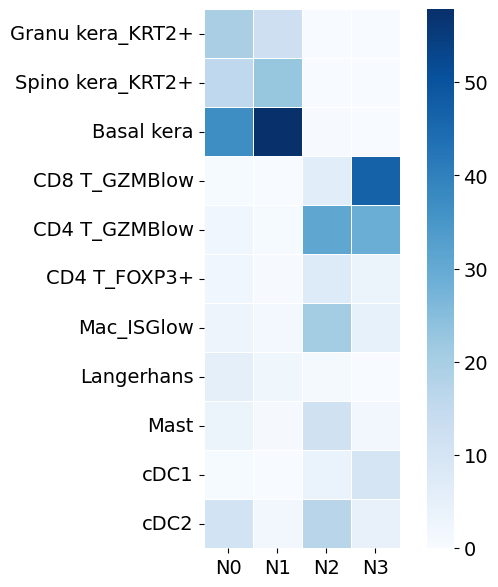

In [9]:
plt.figure(figsize=(7, 7)) # Optional: Adjust the size of the plot

ax = sns.heatmap(
    data= frequency_table,          # The DataFrame/data to plot
    annot=False,               # Display the correlation values on the heatmap
    cmap='Blues',          # The color map (e.g., 'viridis', 'plasma', 'coolwarm')
    fmt=".2f",                # String format for annotation values
    linewidths=.5,            # Space between cells
    annot_kws={"fontsize": 16}, square = True
)


# Set the font size for the x and y tick labels
ax.set_xticklabels(ax.get_xticklabels(), fontsize=14)
ax.set_yticklabels(ax.get_yticklabels(), fontsize=14)


# Access the colorbar and set the size of its tick labels
cbar = ax.collections[0].colorbar
cbar.ax.tick_params(labelsize=14) # 'labelsize' parameter sets the tick label font size

plt.show()